# Unknown item rejection walkthrough

This notebook studies the first open set validation experiment for the Usagi visual identifier. The goal is no longer only to rank the seven known dolls. The system must also recognize when a photograph does not match any known catalog identity.

Session 1 supplies the known reference gallery. Session 2 supplies known validation queries. Session 4 supplies four unknown physical products. Session 3 remains sealed.

## 1. The decision being evaluated

For every query, frozen DINOv2 produces a normalized embedding. Nearest image retrieval finds the training photograph with the highest cosine similarity. That top score becomes the confidence value.

The decision rule is simple:

```text
top cosine score at or above the threshold  →  accept the predicted identity
top cosine score below the threshold        →  return unknown
```

The threshold is selected using validation data only. It minimizes unknown false acceptance while correctly identifying and accepting at least 95 percent of known validation queries.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not locate the project root")
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORT_PATH = (
    PROJECT_ROOT
    / "artifacts/evaluations/dinov2_small/unknown_rejection_validation.json"
)
EMBEDDING_PATH = (
    PROJECT_ROOT / "artifacts/embeddings/facebook_dinov2-small/embeddings.npz"
)
PROCESSED_ROOT = PROJECT_ROOT / "data/processed"

with REPORT_PATH.open(encoding="utf-8") as handle:
    report = json.load(handle)

with np.load(EMBEDDING_PATH, allow_pickle=False) as saved:
    artifact_image_ids = [str(value) for value in saved["image_ids"].tolist()]
    artifact_paths = [
        str(value) for value in saved["processed_relative_paths"].tolist()
    ]

image_path_by_id = dict(zip(artifact_image_ids, artifact_paths, strict=True))

identity_names = {
    "usagi-0001": "Matcha ice cream",
    "usagi-0002": "Airport",
    "usagi-0003": "Bakery",
    "usagi-0004": "Magical",
    "usagi-0005": "Pompompurin",
    "usagi-0006": "Chiikawa Park fluffy",
    "usagi-0007": "Lobster claws",
    "unknown-0001": "Crocheted banana",
    "unknown-0002": "Crocheted rabbit",
    "unknown-0003": "Usagi posture pal",
    "unknown-0004": "Sloth plush",
}

queries = pd.DataFrame(report["queries"])
queries["identity_name"] = queries["true_identity"].map(identity_names)
queries["predicted_name"] = queries["predicted_identity"].map(identity_names)
queries["decision"] = np.where(queries["accepted"], "accepted", "rejected")
threshold = float(report["selected"]["threshold"])

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 80)

print(f"Session 3 accessed: {False}")
print(f"Known validation queries: {report['known_query_count']}")
print(f"Unknown validation queries: {report['unknown_query_count']}")
print(f"Selected threshold: {threshold:.6f}")

Session 3 accessed: False
Known validation queries: 42
Unknown validation queries: 51
Selected threshold: 0.820814


## 2. What each result means

Known acceptance is the fraction of known Session 2 photographs that are allowed through the threshold. Correct known acceptance is stricter. A known photograph must be accepted and assigned the correct identity.

Accepted known accuracy asks whether the known predictions that survived the threshold were correct. Unknown false acceptance is the fraction of unknown photographs that were incorrectly allowed through as known dolls.

In [2]:
selected = report["selected"]
selected_summary = pd.DataFrame(
    {
        "Metric": [
            "Cosine threshold",
            "Known acceptance",
            "Correct known acceptance",
            "Accepted known accuracy",
            "Unknown false acceptance",
        ],
        "Result": [
            f"{selected['threshold']:.6f}",
            f"{selected['known_acceptance_rate']:.1%}",
            f"{selected['known_correct_acceptance_rate']:.1%}",
            f"{selected['accepted_known_accuracy']:.1%}",
            f"{selected['unknown_false_acceptance_rate']:.1%}",
        ],
        "Count": [
            "",
            f"{selected['known_accepted']} of {report['known_query_count']}",
            f"{selected['known_correct_accepted']} of {report['known_query_count']}",
            f"{selected['known_correct_accepted']} of {selected['known_accepted']}",
            f"{selected['unknown_accepted']} of {report['unknown_query_count']}",
        ],
    }
)
selected_summary

,Metric,Result,Count
0,Cosine threshold,0.820814,
1,Known acceptance,95.2%,40 of 42
2,Correct known acceptance,95.2%,40 of 42
3,Accepted known accuracy,100.0%,40 of 40
4,Unknown false acceptance,13.7%,7 of 51


## 3. Every query score

Each dot below is one validation photograph. The vertical line is the selected threshold. Dots to the right are accepted as known. Dots to the left are rejected as unknown.

The most important pattern is overlap. If known and unknown scores occupy the same region, no single global threshold can separate them perfectly.

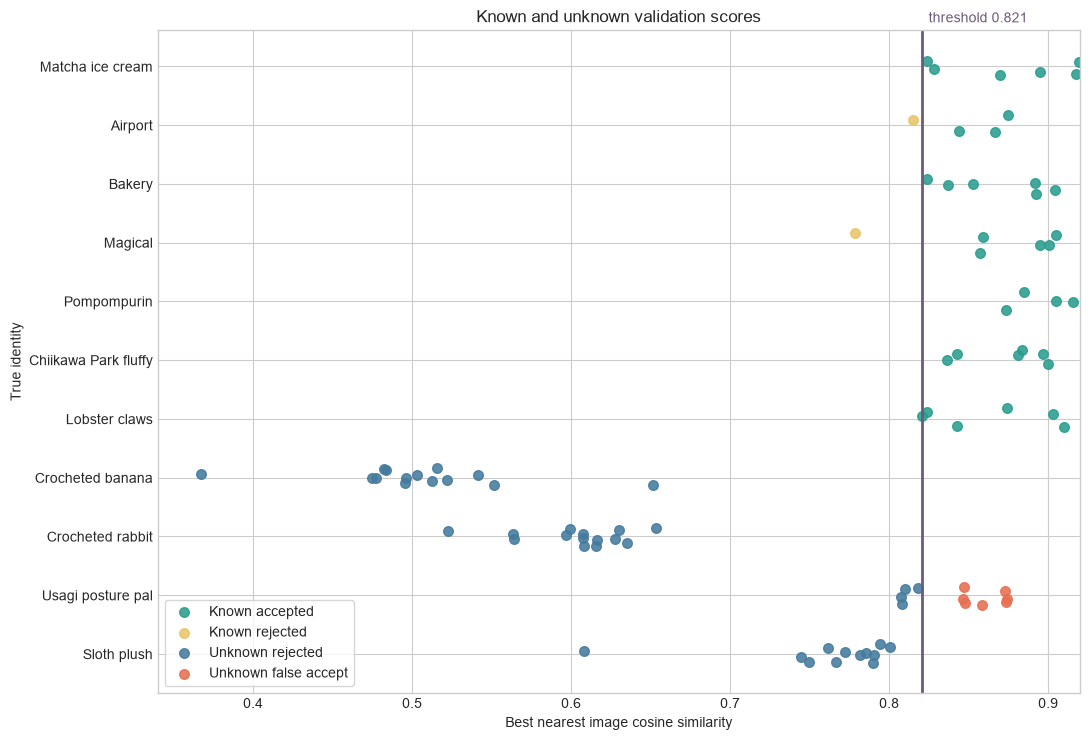

In [3]:
identity_order = [
    "Matcha ice cream",
    "Airport",
    "Bakery",
    "Magical",
    "Pompompurin",
    "Chiikawa Park fluffy",
    "Lobster claws",
    "Crocheted banana",
    "Crocheted rabbit",
    "Usagi posture pal",
    "Sloth plush",
]

decision_colors = {
    "Known accepted": "#2a9d8f",
    "Known rejected": "#e9c46a",
    "Unknown rejected": "#457b9d",
    "Unknown false accept": "#e76f51",
}


def decision_label(row: pd.Series) -> str:
    """Name the known or unknown threshold outcome for one query."""
    if bool(row["is_known"]):
        return "Known accepted" if bool(row["accepted"]) else "Known rejected"
    return "Unknown false accept" if bool(row["accepted"]) else "Unknown rejected"


queries["result_type"] = queries.apply(decision_label, axis=1)
rng = np.random.default_rng(7)

fig, ax = plt.subplots(figsize=(11, 7.5))
for y_position, name in enumerate(identity_order):
    rows = queries[queries["identity_name"] == name]
    for result_type, group in rows.groupby("result_type"):
        jitter = rng.uniform(-0.18, 0.18, size=len(group))
        ax.scatter(
            group["score"],
            y_position + jitter,
            s=48,
            alpha=0.88,
            color=decision_colors[result_type],
            label=result_type,
        )

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles, strict=True))
ax.legend(unique.values(), unique.keys(), loc="lower left", frameon=True)
ax.axvline(threshold, color="#6d597a", linewidth=2, label="Selected threshold")
ax.text(
    threshold + 0.004,
    -0.75,
    f"threshold {threshold:.3f}",
    color="#6d597a",
    fontsize=10,
)
ax.set_yticks(range(len(identity_order)), identity_order)
ax.set_xlabel("Best nearest image cosine similarity")
ax.set_ylabel("True identity")
ax.set_title("Known and unknown validation scores")
ax.set_xlim(0.34, 0.92)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

The three unrelated unknown objects sit below the threshold. Usagi posture pal overlaps heavily with the known score range because it shares the same character, face, ears, colors, and general plush shape as the catalog dolls.

Airport and Magical each have one correctly identified photograph below the threshold. Raising the threshold further would reject more known photographs. Lowering it would accept more unseen Usagi photographs.

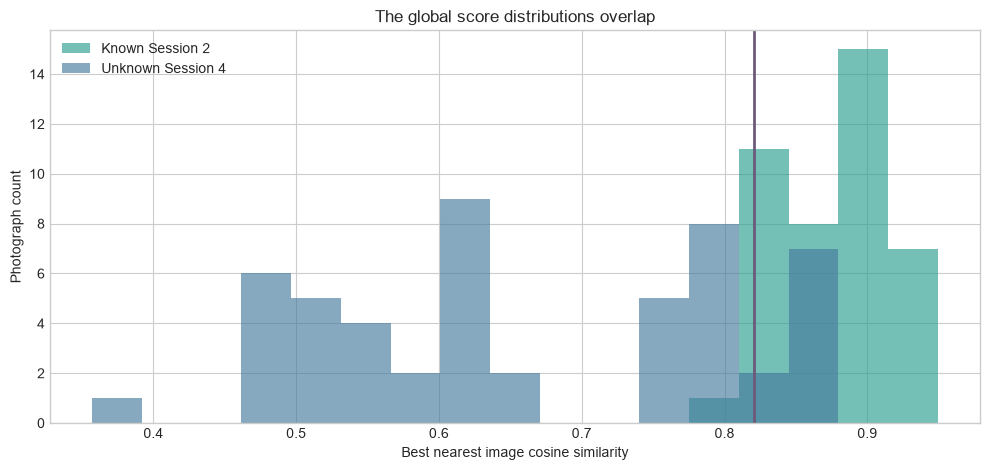

In [4]:
known_scores = queries.loc[queries["is_known"], "score"]
unknown_scores = queries.loc[~queries["is_known"], "score"]

fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.linspace(min(queries["score"]) - 0.01, max(queries["score"]) + 0.01, 18)
ax.hist(known_scores, bins=bins, alpha=0.65, label="Known Session 2", color="#2a9d8f")
ax.hist(
    unknown_scores, bins=bins, alpha=0.65, label="Unknown Session 4", color="#457b9d"
)
ax.axvline(threshold, color="#6d597a", linewidth=2)
ax.set_xlabel("Best nearest image cosine similarity")
ax.set_ylabel("Photograph count")
ax.set_title("The global score distributions overlap")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Results by unknown identity

Breaking the aggregate rate apart shows whether failure is spread across many kinds of objects or concentrated in one difficult identity.

In [5]:
unknown_summary = (
    queries.loc[~queries["is_known"]]
    .groupby(["true_identity", "identity_name"], as_index=False)
    .agg(
        photographs=("image_id", "count"),
        false_accepts=("accepted", "sum"),
        minimum_score=("score", "min"),
        mean_score=("score", "mean"),
        maximum_score=("score", "max"),
    )
)
unknown_summary["false_accept_rate"] = (
    unknown_summary["false_accepts"] / unknown_summary["photographs"]
)
unknown_summary[
    [
        "identity_name",
        "photographs",
        "false_accepts",
        "false_accept_rate",
        "minimum_score",
        "mean_score",
        "maximum_score",
    ]
].style.format(
    {
        "false_accept_rate": "{:.1%}",
        "minimum_score": "{:.3f}",
        "mean_score": "{:.3f}",
        "maximum_score": "{:.3f}",
    }
)

,identity_name,photographs,false_accepts,false_accept_rate,minimum_score,mean_score,maximum_score
0,Crocheted banana,14,0,0.0%,0.367,0.505,0.651
1,Crocheted rabbit,14,0,0.0%,0.522,0.603,0.653
2,Usagi posture pal,11,7,63.6%,0.807,0.842,0.874
3,Sloth plush,12,0,0.0%,0.608,0.762,0.801


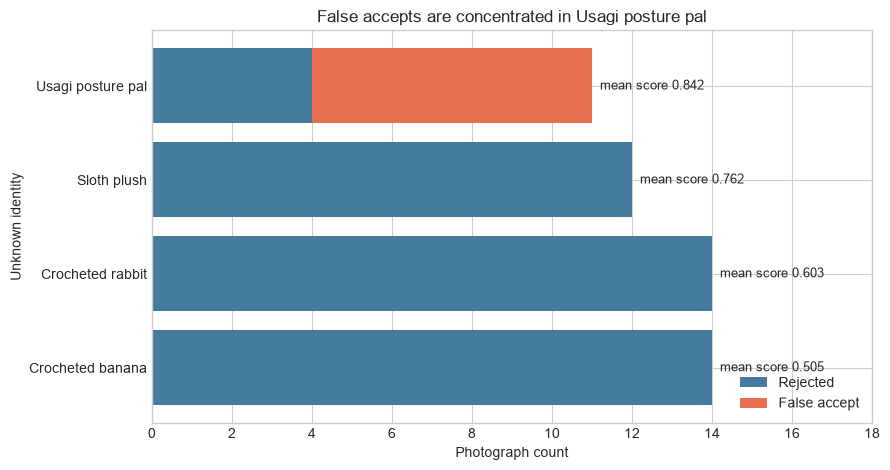

In [6]:
plot_summary = unknown_summary.sort_values("mean_score")
rejected = plot_summary["photographs"] - plot_summary["false_accepts"]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(plot_summary["identity_name"], rejected, color="#457b9d", label="Rejected")
ax.barh(
    plot_summary["identity_name"],
    plot_summary["false_accepts"],
    left=rejected,
    color="#e76f51",
    label="False accept",
)
for row, (_, values) in enumerate(plot_summary.iterrows()):
    ax.text(
        values["photographs"] + 0.2,
        row,
        f"mean score {values['mean_score']:.3f}",
        va="center",
        fontsize=9,
    )
ax.set_xlabel("Photograph count")
ax.set_ylabel("Unknown identity")
ax.set_title("False accepts are concentrated in Usagi posture pal")
ax.legend(loc="lower right")
ax.set_xlim(0, max(plot_summary["photographs"]) + 4)
plt.tight_layout()
plt.show()

## 5. How the threshold was selected

Every unique validation score creates a possible operating point. Moving the threshold downward accepts more known photographs, but it can also accept more unknown photographs.

The selected point is the safest threshold that still preserves the predeclared minimum of 95 percent correct known acceptance. With 42 known photographs, that means at least 40 must be correctly identified and accepted.

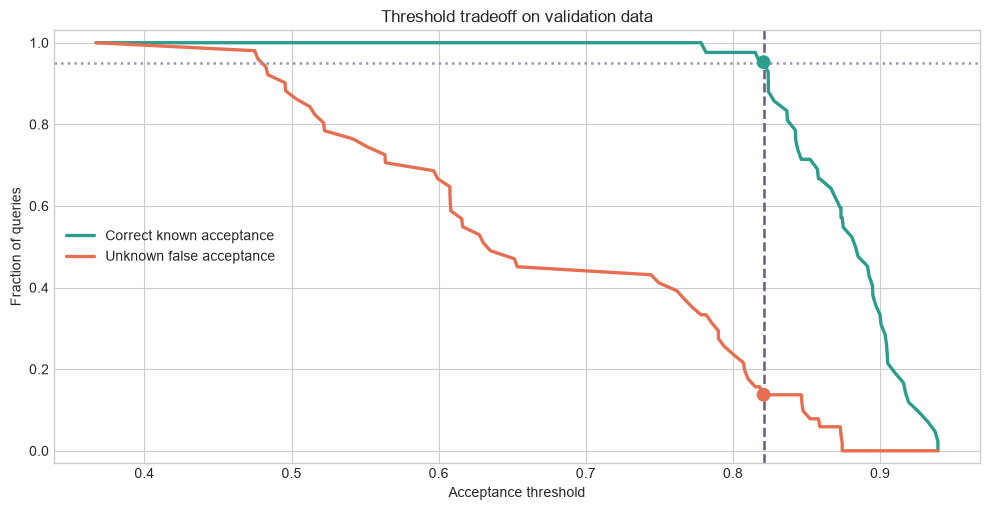

In [7]:
curve = pd.DataFrame(report["curve"]).sort_values("threshold")

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(
    curve["threshold"],
    curve["known_correct_acceptance_rate"],
    color="#2a9d8f",
    linewidth=2.4,
    label="Correct known acceptance",
)
ax.plot(
    curve["threshold"],
    curve["unknown_false_acceptance_rate"],
    color="#e76f51",
    linewidth=2.4,
    label="Unknown false acceptance",
)
ax.axhline(0.95, color="#8d99ae", linestyle=":", linewidth=1.8)
ax.axvline(threshold, color="#6d597a", linestyle="--", linewidth=1.8)
ax.scatter(
    [threshold, threshold],
    [
        selected["known_correct_acceptance_rate"],
        selected["unknown_false_acceptance_rate"],
    ],
    color=["#2a9d8f", "#e76f51"],
    s=80,
    zorder=3,
)
ax.set_xlabel("Acceptance threshold")
ax.set_ylabel("Fraction of queries")
ax.set_title("Threshold tradeoff on validation data")
ax.set_ylim(-0.03, 1.03)
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

The curve does not reveal a perfect separator. That is the important result. The threshold is behaving as designed, but the score itself is not sufficiently discriminative for an unseen variant of the same character.

## 6. The four unknown products

These examples show the visual difficulty represented by each unknown identity. The first, second, and final photographs are displayed for each product.

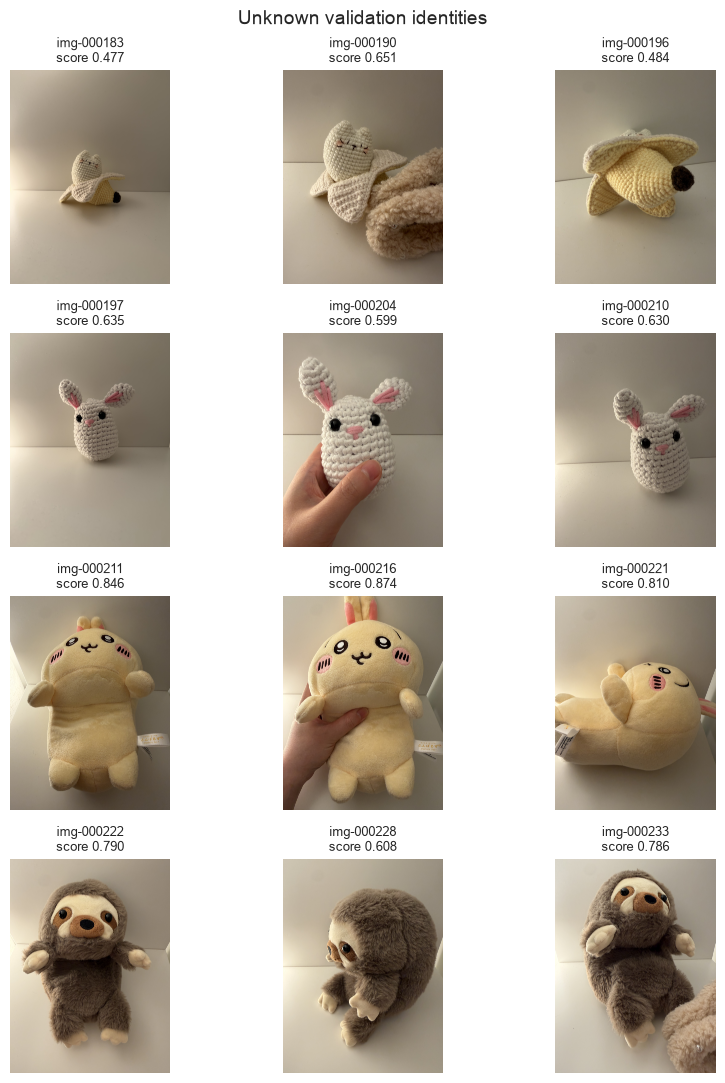

In [8]:
def load_processed_image(image_id: str) -> Image.Image:
    """Load one prepared photograph by its stable image ID."""
    path = PROCESSED_ROOT / image_path_by_id[image_id]
    with Image.open(path) as opened:
        return opened.convert("RGB")


unknown_groups = list(queries.loc[~queries["is_known"]].groupby("true_identity"))
fig, axes = plt.subplots(len(unknown_groups), 3, figsize=(9, 11))
for row, (identity_id, group) in enumerate(unknown_groups):
    indices = [0, len(group) // 2, len(group) - 1]
    for column, group_index in enumerate(indices):
        item = group.iloc[group_index]
        image = load_processed_image(str(item["image_id"]))
        axes[row, column].imshow(image)
        axes[row, column].axis("off")
        axes[row, column].set_title(
            f"{item['image_id']}\nscore {item['score']:.3f}", fontsize=9
        )
    axes[row, 0].set_ylabel(identity_names[identity_id], fontsize=11)

fig.suptitle("Unknown validation identities", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Every false acceptance

The left column shows the unknown query. The right column shows the known Session 1 reference that produced the highest cosine similarity. These pairs make it possible to judge whether the model is matching a meaningful product detail or only broad character appearance.

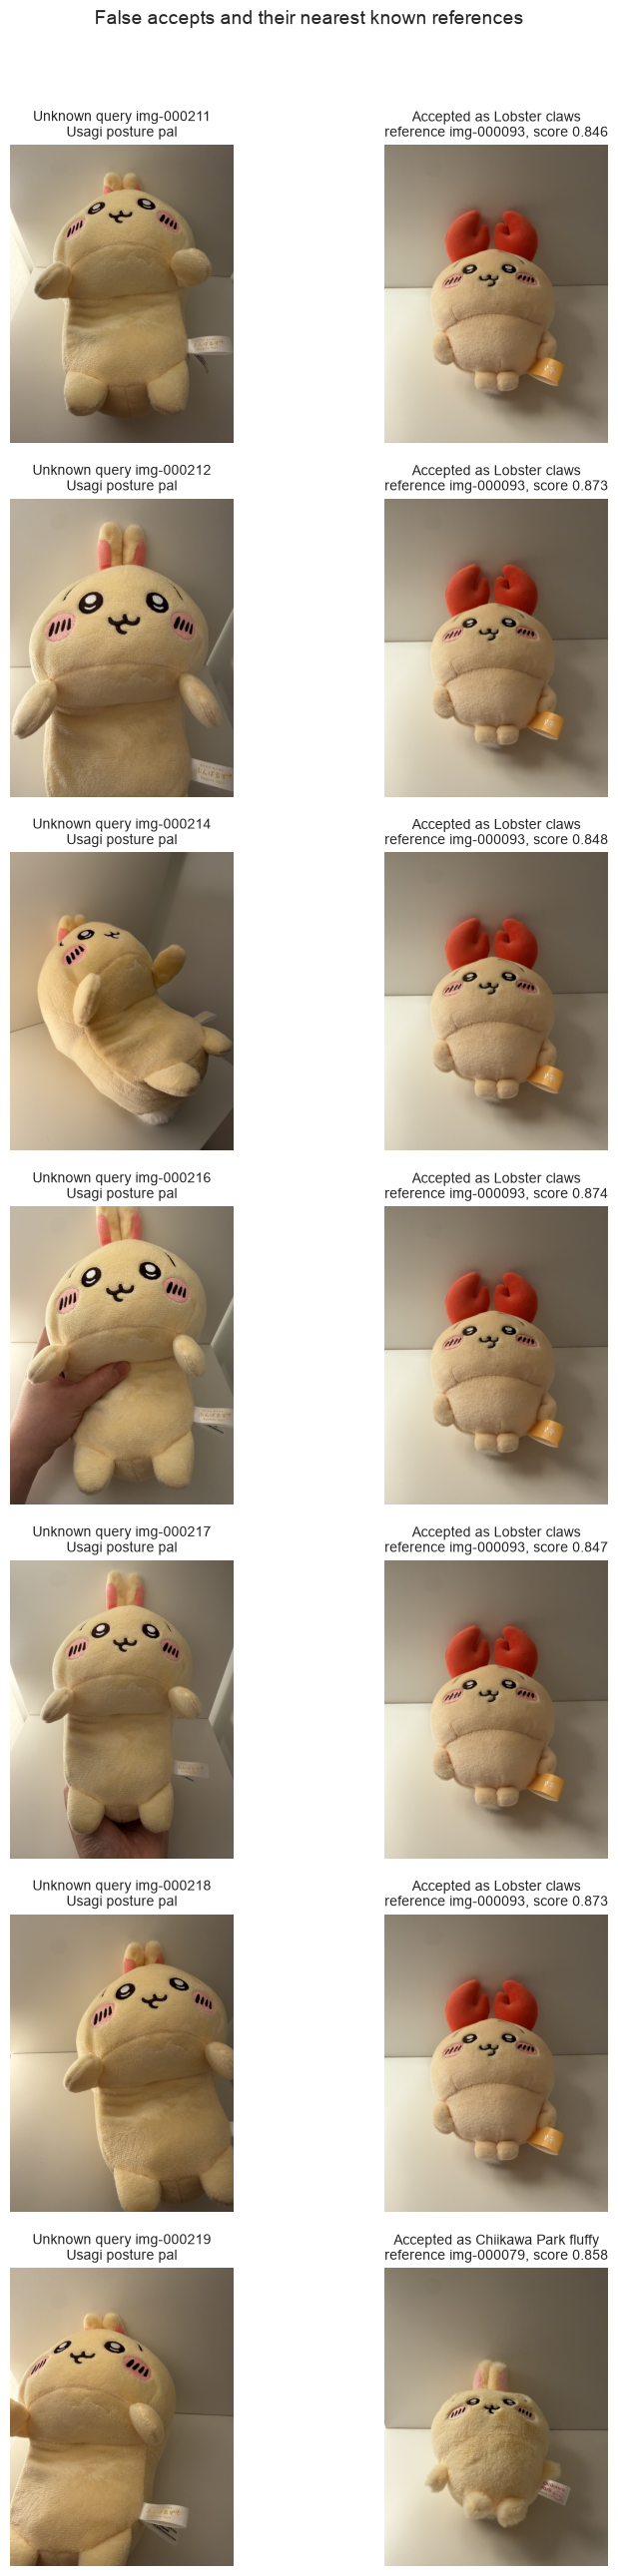

In [9]:
false_accepts = queries.loc[(~queries["is_known"]) & queries["accepted"]].copy()
fig, axes = plt.subplots(len(false_accepts), 2, figsize=(9, 3.7 * len(false_accepts)))

for row, (_, item) in enumerate(false_accepts.iterrows()):
    query_image = load_processed_image(str(item["image_id"]))
    reference_id = str(item["reference_image_id"])
    reference_image = load_processed_image(reference_id)

    axes[row, 0].imshow(query_image)
    axes[row, 0].axis("off")
    axes[row, 0].set_title(
        f"Unknown query {item['image_id']}\nUsagi posture pal", fontsize=10
    )

    axes[row, 1].imshow(reference_image)
    axes[row, 1].axis("off")
    axes[row, 1].set_title(
        f"Accepted as {item['predicted_name']}\n"
        f"reference {reference_id}, score {item['score']:.3f}",
        fontsize=10,
    )

fig.suptitle("False accepts and their nearest known references", fontsize=14, y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.975), h_pad=1.5)
plt.show()

Six posture pal photographs choose Lobster claws, and one chooses Chiikawa Park fluffy. The shared Usagi face and body dominate even though the defining accessories do not match. This is exactly the kind of error that unrelated negative examples cannot reveal.

## 8. Known photographs rejected by the threshold

Both rejected known photographs were still ranked as the correct identity. Their scores were simply below the global acceptance threshold. This separates ranking correctness from confidence calibration.

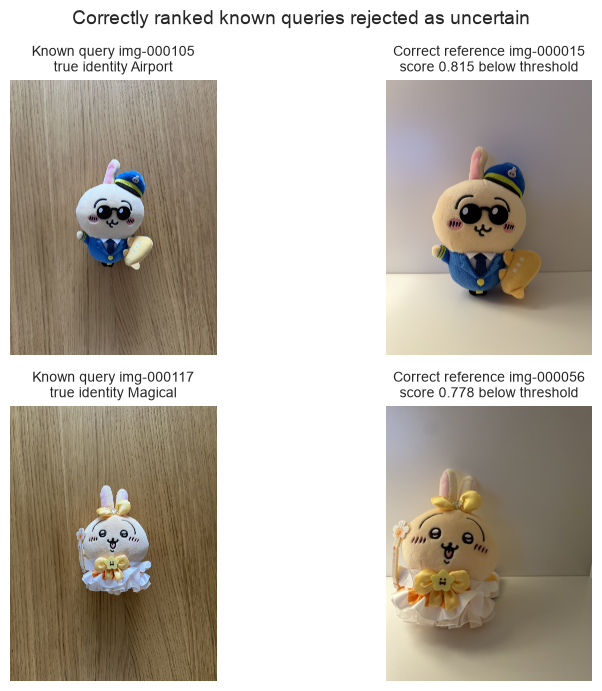

In [10]:
known_rejections = queries.loc[queries["is_known"] & ~queries["accepted"]].copy()
fig, axes = plt.subplots(
    len(known_rejections), 2, figsize=(9, 3.5 * len(known_rejections))
)
axes = np.atleast_2d(axes)

for row, (_, item) in enumerate(known_rejections.iterrows()):
    query_image = load_processed_image(str(item["image_id"]))
    reference_id = str(item["reference_image_id"])
    reference_image = load_processed_image(reference_id)

    axes[row, 0].imshow(query_image)
    axes[row, 0].axis("off")
    axes[row, 0].set_title(
        f"Known query {item['image_id']}\ntrue identity {item['identity_name']}",
        fontsize=10,
    )

    axes[row, 1].imshow(reference_image)
    axes[row, 1].axis("off")
    axes[row, 1].set_title(
        f"Correct reference {reference_id}\nscore {item['score']:.3f} below threshold",
        fontsize=10,
    )

fig.suptitle("Correctly ranked known queries rejected as uncertain", fontsize=14)
plt.tight_layout()
plt.show()

## 9. What this experiment changes

The frozen retrieval model is already strong at ranking known dolls, but maximum cosine similarity alone is not enough for reliable unknown rejection. The aggregate 13.7 percent false acceptance rate hides a much larger problem for the difficult unknown identity: 7 of 11 Usagi posture pal photographs were accepted.

The next evaluation should compare additional confidence signals on the same validation set:

1. The gap between the first and second identity scores.
2. Agreement among several nearest reference photographs.
3. A separate threshold for each predicted identity.
4. Distance to each identity prototype in addition to the nearest photograph.

The current threshold remains a useful baseline. Session 3 must stay sealed while these choices are compared and frozen.

In [11]:
final_summary = pd.DataFrame(
    {
        "Question": [
            "Can unrelated objects be rejected?",
            "Can an unseen Usagi variant be rejected reliably?",
            "Are accepted known predictions correct?",
            "Is the final test set still sealed?",
        ],
        "Finding": [
            "Yes. Banana, crocheted rabbit, and sloth had zero false accepts.",
            "Not yet. Usagi posture pal had 7 false accepts in 11 photographs.",
            "Yes. All 40 accepted known photographs were correctly identified.",
            "Yes. Session 3 was not included in the embedding artifact.",
        ],
    }
)
final_summary

,Question,Finding
0,Can unrelated objects be rejected?,"Yes. Banana, crocheted rabbit, and sloth had zero false accepts."
1,Can an unseen Usagi variant be rejected reliably?,Not yet. Usagi posture pal had 7 false accepts in 11 photographs.
2,Are accepted known predictions correct?,Yes. All 40 accepted known photographs were correctly identified.
3,Is the final test set still sealed?,Yes. Session 3 was not included in the embedding artifact.


© 2026 Emma Tong. All rights reserved.